<a href="https://colab.research.google.com/github/Swetha0407/Computer-vision/blob/main/Exp27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install opencv-contrib-python==4.10.0.84

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 16.9 MB/s  0:00:04
  Attempting uninstall: opencv-contrib-python
    Found existing installation: opencv-contrib-python 4.14.0.94
    Uninstalling opencv-contrib-python-4.14.0.94:
      Successfully uninstalled opencv-contrib-python-4.14.0.94


Saving face_detection_input.jpg to face_detection_input.jpg
Image uploaded successfully: face_detection_input.jpg
OpenCV version: 4.10.0
Number of faces detected: 1


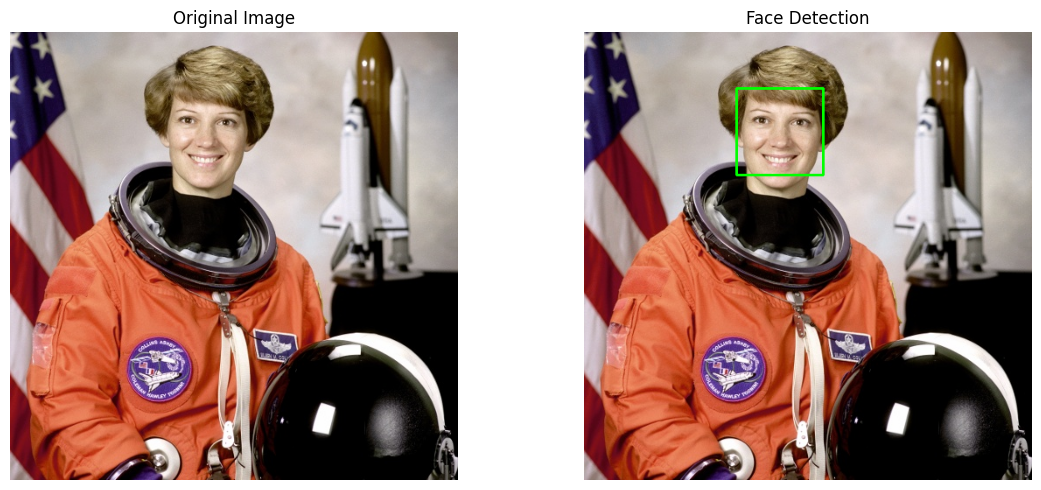

In [3]:
from google.colab import files
uploaded = files.upload()

import cv2
import matplotlib.pyplot as plt

# Read uploaded image
filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

if image is None:
    raise ValueError("Could not read the uploaded image.")

print("Image uploaded successfully:", filename)
print("OpenCV version:", cv2.__version__)

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Load Haar Cascade face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

if face_cascade.empty():
    raise RuntimeError("Could not load face detection model.")

# Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(80, 80)
)

# Draw rectangles around detected faces
result = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

print("Number of faces detected:", len(faces))

# Display original and detected images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Face Detection")
plt.axis("off")

plt.tight_layout()
plt.show()